# Semana 7: Importancia de variables

Título provisional: Generalización de políticas de aprendizaje por refuerzo ante diferentes niveles de fidelidad

Alumno: Brayan Bruce Pérez Escobar

Rama: `sprint4-importanciaDevariables`

## Resultados preliminares

En el Sprint 3 se entrenó PPO en R3 con tres versiones de la observación: el baseline con las 11 features, la Var1 que agrega el margen de control y la Var2 que quita la fase del pulso. Lo demás quedó igual (algoritmo, recompensa, física y semillas). En R3 las tres llegaron al mismo η, pero al evaluarlas en R1 donde no hay flujo el resultado cambió bastante:

| Variante | η R3 | η R1 |
|---|---|---|
| Baseline | 0.968 | 0.335 |
| Var1 · + margen | 0.966 | 0.000 |
| Var2 · − fase | 0.965 | 0.972 |

El baseline solo transfirió con una de las tres semillas, la Var1 no transfirió con ninguna y la Var2 transfirió con las tres. Con eso se eligió la Var2 como candidata, pero quedó sin responder por qué pasó ello. 

Debido a que solo se habían probado dos cambios (la fase y el margen) y no se sabía qué variables usa realmente la política para decidir, ni si las otras features también influyen en la falla en R1. Eso es lo que se busca en esta semana midiendo la importancia de cada variable.

Para este reporte:

- Para esta semana no se entrena nada nuevo, solo se evalúa las tres variantes que parten de las 3 semillas, esto es 9 "modelos". Se analizan las 9 políticas, todas entrenadas en R3.

| Variante | Semilla 0 | Semilla 1 | Semilla 2 |
|---|---|---|---|
| Baseline (11 features) | base_R3_s0 | base_R3_s1 | base_R3_s2 |
| Var1 · + margen | margen_R3_s0 | margen_R3_s1 | margen_R3_s2 |
| Var2 · − fase | sin_fase_R3_s0 | sin_fase_R3_s1 | sin_fase_R3_s2 |

Cada semilla ha servido para poder confirmar que un resultado se repite o solo fue azar.

- Se compara los resultados entre semillas de entrenamiento: 3 semillas.


## Descripción de lo conseguido en la última semana: Las variables 

En el código del entorno las features tienen nombre en inglés. Aquí se muestran en español:

| Grupo | Feature(s) | Qué le dice al agente |
|---|---|---|
| centroide_x, centroide_y | `centroid_x`, `centroid_y` | Dónde está el centro del enjambre, respecto al vértice |
| dispersion_x, dispersion_y | `spread_x`, `spread_y` | Qué tan disperso está el enjambre |
| fracciones | `frac_target`, `frac_other`, `frac_active` | Fracción entregada, perdida y activa |
| fase | `phase_sin`, `phase_cos` | Momento del pulso del flujo |
| accion_previa_x, accion_previa_y | `prev_action_x`, `prev_action_y` | Fuerza aplicada en el paso anterior |
| margen_control (solo Var1) | `control_margin` | $F_{\max}/(F_{\max}+U(t))$ |



In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nanoswarm.agents.ppo_sb3 import FrozenPolicy
from nanoswarm.envs.features import feature_names
from nanoswarm.evaluation import ROOT, episode_seeds
from nanoswarm.importancia import (GRUPOS, NOMBRES, SEMILLAS_BANCO, banco, grupos_de, importancia,
                                   importancia_permutacion)
from nanoswarm.utils.rollout import run_metadata

T_INICIO = time.time()
pd.set_option("display.precision", 3)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "figure.dpi": 110})
FS = ["base", "margen", "sin_fase"]
FS_ETIQUETA = {"base": "Baseline (11 features)", "margen": "Var1 · + margen", "sin_fase": "Var2 · − fase"}
FS_COLOR = {"base": "#2a78d6", "margen": "#eb6834", "sin_fase": "#1baf7a"}
NIVEL_COLOR = {"R1": "#2a78d6", "R2": "#eb6834", "R3": "#1baf7a", "R4": "#eda100"}
SEMILLAS_ENTREN = [0, 1, 2]
PILOTO = ROOT / "experiments" / "pilot"
CORRIDAS = [PILOTO / f"{fs}_R3_s{s}" for fs in FS for s in SEMILLAS_ENTREN]

# Cada resultado se guarda en disco para armar las tablas finales con datos reales
TABLAS = ROOT / "results" / "tables"
FIGURAS = ROOT / "results" / "figures"
RECALCULAR = False  # False: si la tabla de la sección 2 ya existe, se carga en vez de volver a correr
NIVELES = ["R3", "R1"]  # nivel de entrenamiento y nivel donde falla la transferencia
TOP = 5  # tamaño del top para la estabilidad entre semillas (sección 4)


def guardar(df, nombre, index=False):
    ruta = TABLAS / f"sprint4_{nombre}.csv"
    df.to_csv(ruta, index=index)
    print(f"Guardado: {ruta.relative_to(ROOT)}")


def leer(nombre, **kw):
    return pd.read_csv(TABLAS / f"sprint4_{nombre}.csv", **kw)


print(json.dumps(run_metadata(), indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-30T18:43:37",
  "git_commit": "fb938e6 (con cambios sin commit)",
  "python": "3.12.7",
  "plataforma": "Windows-11-10.0.26300-SP0",
  "numpy": "2.5.3",
  "gymnasium": "1.4.0",
  "pandas": "3.0.6"
}


## 1. Metodo

### 1.1 Objetivo

Se quiere saber qué variables de la observación usa la política para decidir y si las que usa en R3 son las mismas que la hacen fallar cuando se evalúa en R1. Con eso se decide qué features pasan a la observación del experimento principal.

### 1.2 Importancia por permutación adaptada a RL

La importancia se calcula como

$$\text{importancia}_j = \eta_{\text{original}} - \eta_{\text{permutado}}$$

usando las mismas semillas de episodio en los dos casos, para que la comparación sea pareada.

Si la importancia es alta la política depende de esa variable, si está cerca de 0 la ignora, y si es negativa la variable estorba, es decir, sin ella la política rinde mejor.

Se usan las semillas de ajuste (5000 a 5019) y no las de reporte porque elegir qué features se quedan es una decisión. Si se decidiera con las semillas de reporte, después esas mismas semillas ya no servirían para medir el resultado final sin sesgo. Sería como elegir el modelo mirando el test.

### 1.3 Grupos de features

Algunas features representan una misma cantidad y por eso se permutan juntas. La fase se guarda como fase_sen y fase_cos, que son dos números para un solo ángulo. Las fracciones entregada, perdida y activa siempre suman 1 (en la semana 6 su VIF salió infinito).

Si se permutara solo una de ellas, la política todavía podría sacar la información de la otra. Por ejemplo, si se esconde fase_sen pero se deja fase_cos, la red sigue sabiendo más o menos en qué momento del pulso está, η casi no baja y la fase parecería poco importante aunque no lo sea. Permutando el grupo completo se evita subestimar su importancia.

In [2]:
tabla_grupos = pd.DataFrame([{"conjunto": FS_ETIQUETA[fs], "grupo": g,
                              "features": ", ".join(NOMBRES[c] for c in GRUPOS[g])}
                             for fs in FS for g in grupos_de(fs)])
guardar(tabla_grupos, "grupos")
tabla_grupos.pivot(index="grupo", columns="conjunto", values="features").reindex(GRUPOS).fillna("—")

Guardado: results\tables\sprint4_grupos.csv


conjunto,Baseline (11 features),Var1 · + margen,Var2 · − fase
grupo,,,
centroide_x,centroide_x,centroide_x,centroide_x
centroide_y,centroide_y,centroide_y,centroide_y
dispersion_x,dispersion_x,dispersion_x,dispersion_x
dispersion_y,dispersion_y,dispersion_y,dispersion_y
fracciones,"frac_entregada, frac_perdida, frac_activa","frac_entregada, frac_perdida, frac_activa","frac_entregada, frac_perdida, frac_activa"
fase,"fase_sen, fase_cos","fase_sen, fase_cos",—
accion_previa_x,accion_previa_x,accion_previa_x,accion_previa_x
accion_previa_y,accion_previa_y,accion_previa_y,accion_previa_y
margen_control,—,margen_control,—


### 1.4 Ejemplo: cómo se ve el banco

Resumen del banco de una política (baseline, semilla 0), con los nombres en español.

In [3]:
politica = FrozenPolicy(PILOTO / "base_R3_s0")
banco_obs, banco_acc, banco_ep = banco(politica)
tabla_banco = pd.DataFrame(banco_obs, columns=[NOMBRES[c] for c in feature_names("base")])
print(f"{len(tabla_banco)} observaciones de {banco_ep.max() + 1} episodios")
resumen_banco = tabla_banco.describe().T[["mean", "std", "min", "max"]]
guardar(resumen_banco, "banco_base_s0", index=True)
resumen_banco

1449 observaciones de 10 episodios
Guardado: results\tables\sprint4_banco_base_s0.csv


,mean,std,min,max
centroide_x,-8.815e-01,2.525e+00,-4.904,3.431
centroide_y,6.299e-01,5.293e-01,-0.031,1.950
dispersion_x,7.261e-01,4.038e-01,0.043,1.266
dispersion_y,2.227e-01,1.320e-01,0.020,0.570
frac_entregada,1.238e-01,2.367e-01,0.000,0.930
frac_perdida,1.208e-04,7.679e-04,0.000,0.005
frac_activa,8.761e-01,2.368e-01,0.070,1.000
fase_sen,7.215e-01,2.931e-01,0.000,1.000
fase_cos,3.402e-01,5.273e-01,-0.649,1.000
accion_previa_x,8.355e-01,1.449e-01,0.000,1.000


## 2. Importancia en el nivel de entrenamiento (R3)

Se corren las 9 políticas en R3 y en R1, con 20 episodios por grupo usando las semillas de ajuste. Tarda alrededor de 12 minutos.

Antes, como lo mecionado en las notas preliminares, se espera que la fase fuera la variable más importante del baseline en R3, porque es la única que le dice a la política en qué momento del pulso está, y en el Sprint 3 quitarla fue lo que más cambió el resultado.

In [16]:
SEMILLAS_EP = episode_seeds("ajuste")  # 5000–5019
if RECALCULAR or not (TABLAS / "sprint4_episodios_permutacion.csv").exists():
    t0 = time.time()
    episodios = importancia_permutacion(CORRIDAS, NIVELES, SEMILLAS_EP)
    print(f"{len(episodios)} episodios en {(time.time() - t0) / 60:.1f} min")
    guardar(episodios, "episodios_permutacion")  # η de cada episodio (crudo)
else:
    episodios = leer("episodios_permutacion")
    print(f"Cargados {len(episodios)} episodios ya calculados (RECALCULAR = True para volver a correr)")
imp = importancia(episodios)
guardar(imp, "importancia")  # importancia por corrida, nivel y grupo

Cargados 3240 episodios ya calculados (RECALCULAR = True para volver a correr)
Guardado: results\tables\sprint4_importancia.csv


In [17]:
def resumen(imp, condicion):
    """Importancia media y desviación entre semillas de entrenamiento, por conjunto y grupo."""
    t = (imp[imp["condicion"] == condicion]
         .groupby(["feature_set", "grupo"])["importancia"].agg(["mean", "std"]).unstack(0))
    t.columns = [f"{FS_ETIQUETA[fs]} · {m}" for m, fs in t.columns]
    return t.reindex(GRUPOS).dropna(how="all")


def graficar(imp, condiciones, archivo):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
    alto = 0.8 / len(condiciones)
    for ax, fs in zip(axes, FS):
        grupos = list(grupos_de(fs))
        y = np.arange(len(grupos))
        for k, c in enumerate(condiciones):
            t = imp[(imp["feature_set"] == fs) & (imp["condicion"] == c)].groupby("grupo")["importancia"]
            ax.barh(y + k * alto, t.mean().reindex(grupos), xerr=t.std().reindex(grupos), height=alto,
                    color=NIVEL_COLOR[c], label=c, capsize=2)
        ax.set_yticks(y + alto * (len(condiciones) - 1) / 2, grupos)
        ax.invert_yaxis()
        ax.axvline(0, color="#555", lw=0.8)
        ax.set_title(FS_ETIQUETA[fs])
        ax.set_xlabel("Importancia = η original − η permutado")
    axes[0].legend(title="Evaluado en")
    fig.tight_layout()
    fig.savefig(FIGURAS / archivo, bbox_inches="tight", dpi=130)
    plt.show()


resumen_R3 = resumen(imp, "R3")
guardar(resumen_R3, "resumen_R3", index=True)
resumen_R3

Guardado: results\tables\sprint4_resumen_R3.csv


,Baseline (11 features) · mean,Var1 · + margen · mean,Var2 · − fase · mean,Baseline (11 features) · std,Var1 · + margen · std,Var2 · − fase · std
grupo,,,,,,
centroide_x,0.003,-0.007,5.075e-02,0.008,0.003,0.089
centroide_y,0.145,0.005,8.558e-02,0.184,0.009,0.150
dispersion_x,0.007,0.012,1.792e-02,0.008,0.005,0.033
dispersion_y,0.019,-0.004,1.175e-02,0.042,0.004,0.017
fracciones,0.159,0.041,3.169e-01,0.227,0.050,0.294
fase,0.053,0.239,NaN,0.036,0.193,NaN
accion_previa_x,-0.004,0.002,4.167e-04,0.003,0.002,0.003
accion_previa_y,0.002,0.002,5.250e-03,0.005,0.005,0.009
margen_control,NaN,-0.003,NaN,NaN,0.005,NaN


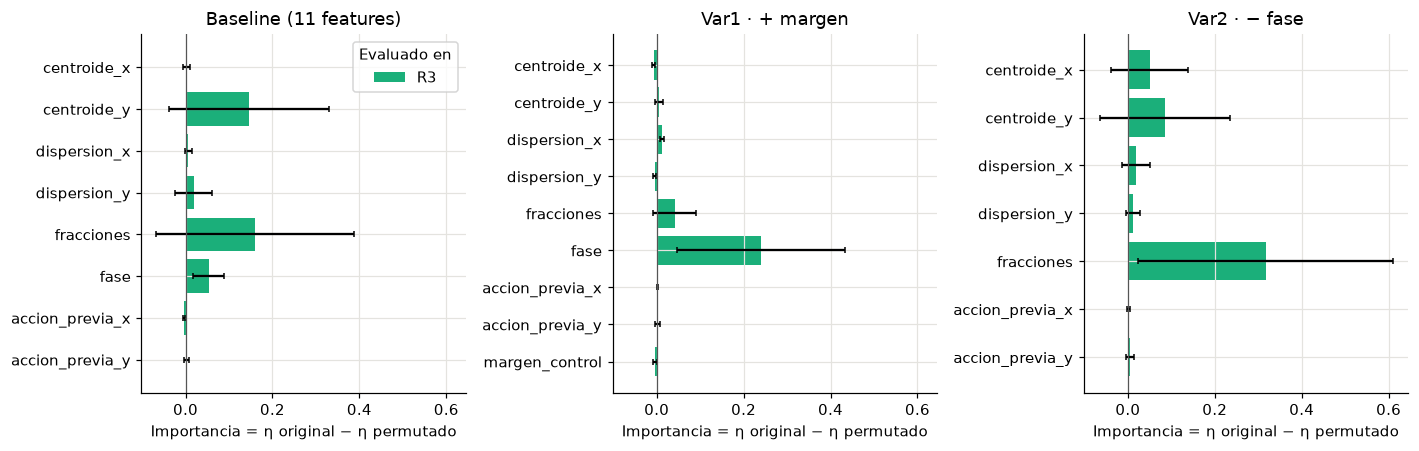

In [18]:
graficar(imp, ["R3"], "figura7_importancia_R3.png")

En R3 las variables más importantes son las fracciones y el centroide. En el baseline la importancia media de las fracciones es 0.159 y la del centroide_y 0.145, y en la Var2 las fracciones llegan a 0.317. La fase sí se usa, pero en el baseline menos de lo esperado (0.053). En la Var1 es diferente: ahí la fase es la variable más importante (0.239), mientras que el margen casi no se usa en R3 (−0.003).



## 3. Importancia (R1)

En R1 no hay flujo y es donde el baseline transfiere mal (η = 0.335 en la semana 6). Si una variable es importante en R3 pero en R1 su valor significa otra cosa, la política se guía mal. El banco sigue siendo el de R3 porque tiene los valores que la política conoce.

La hipótesis es que en las políticas que fallan en R1 hay variables con importancia negativa, es decir, que empeoran el η en sentido que al esconderlas η sube. Se espera que la fase y el margen sean esas variables, porque son las que cambian de comportamiento entre R3 y R1.

In [7]:
resumen_R1 = resumen(imp, "R1")
guardar(resumen_R1, "resumen_R1", index=True)
resumen_R1

Guardado: results\tables\sprint4_resumen_R1.csv


,Baseline (11 features) · mean,Var1 · + margen · mean,Var2 · − fase · mean,Baseline (11 features) · std,Var1 · + margen · std,Var2 · − fase · std
grupo,,,,,,
centroide_x,0.333,0.000,-4.833e-03,0.553,0.000,0.008
centroide_y,0.010,0.000,7.500e-04,0.969,0.000,0.008
dispersion_x,-0.027,0.000,3.207e-01,0.063,0.000,0.558
dispersion_y,-0.281,0.000,3.333e-04,0.488,0.000,0.003
fracciones,0.007,0.000,-3.083e-03,0.018,0.000,0.003
fase,-0.312,-0.320,NaN,0.540,0.555,NaN
accion_previa_x,-0.362,0.000,4.167e-04,0.524,0.000,0.002
accion_previa_y,-0.224,0.000,-1.417e-03,0.380,0.000,0.002
margen_control,NaN,-0.322,NaN,NaN,0.551,NaN


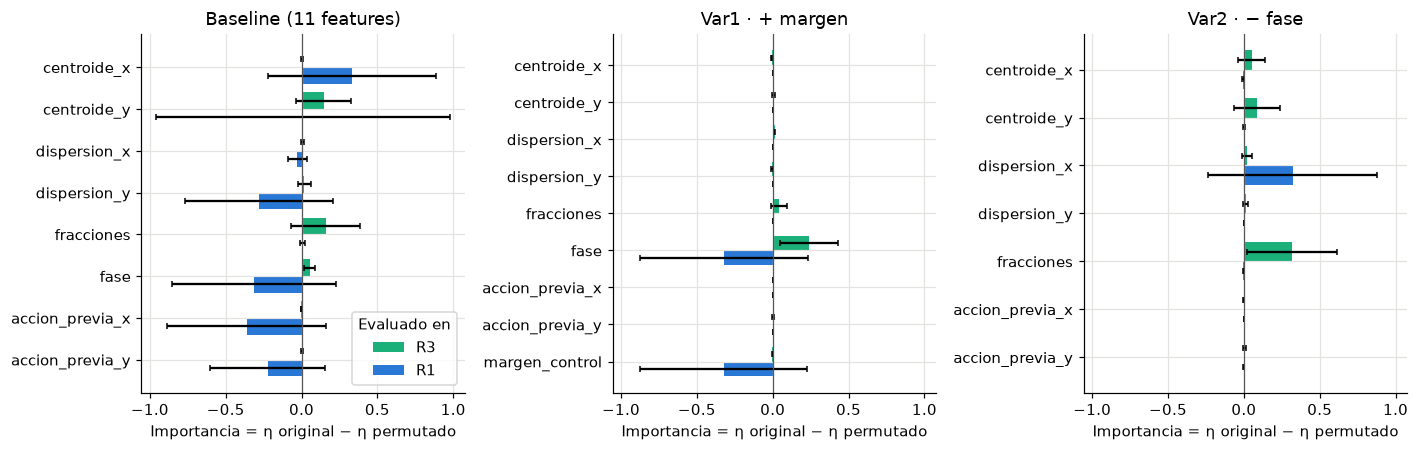

In [8]:
graficar(imp, ["R3", "R1"], "fig8_sprint4_importancia_R3_R1.png")

En R1 las políticas que fallan sí saben resolver la tarea, pero al esconder la fase, el margen o la acción previa, η sube de casi 0 a 0.97. Son variables que en R1 se comportan distinto a lo que la política vio en R3, y cada semilla depende de una diferente. 

La Var2 no tiene ninguna variable que estorbe en R1, porque se guía por el estado del enjambre, que significa lo mismo en los dos niveles, y por eso transfiere en las tres semillas.

## 4. Estabilidad entre semillas

Para ver si las tres semillas coinciden se usan dos medidas. La primera es el top-5 común, que son las variables que están entre las cinco más importantes en las tres semillas a la vez. La segunda es la correlación de Spearman, que compara el orden de importancia de las variables entre cada par de semillas.


In [9]:
filas = []
for (fs, c), g in imp.groupby(["feature_set", "condicion"]):
    tabla = g.pivot(index="grupo", columns="semilla_entren", values="importancia")
    tops = [set(tabla[s].nlargest(TOP).index) for s in tabla.columns]
    rangos = tabla.rank()
    pares = [rangos[a].corr(rangos[b]) for i, a in enumerate(tabla.columns) for b in tabla.columns[i + 1:]]
    filas.append({"feature_set": fs, "conjunto": FS_ETIQUETA[fs], "nivel": c, "n_grupos": len(tabla),
                  f"top{TOP}_común": ", ".join(sorted(set.intersection(*tops))),
                  "spearman_medio": np.nanmean(pares)})
estabilidad = pd.DataFrame(filas)
guardar(estabilidad, "estabilidad")
estabilidad.drop(columns="feature_set")

Guardado: results\tables\sprint4_estabilidad.csv


,conjunto,nivel,n_grupos,top5_común,spearman_medio
0,Baseline (11 features),R1,8,centroide_x,-0.154
1,Baseline (11 features),R3,8,"centroide_y, dispersion_x, fase",0.429
2,Var1 · + margen,R1,9,"accion_previa_x, accion_previa_y, centroide_x,...",0.250
3,Var1 · + margen,R3,9,"dispersion_x, fase, fracciones",0.722
4,Var2 · − fase,R1,7,"accion_previa_x, dispersion_y",0.067
5,Var2 · − fase,R3,7,"dispersion_y, fracciones",-0.190


En R3 el Spearman va de −0.19 en la Var2 a 0.72 en la Var1, que es la más estable porque sus tres semillas dependen de la fase.  Cada semilla resuelve la tarea con variables distintas, y por eso el baseline transfiere a R1 solo en algunas semillas. 

La Var2 es estable donde importa, en el resultado, con η = 0.97 en R1 en las tres semillas.

## 5. Curvas de aprendizaje



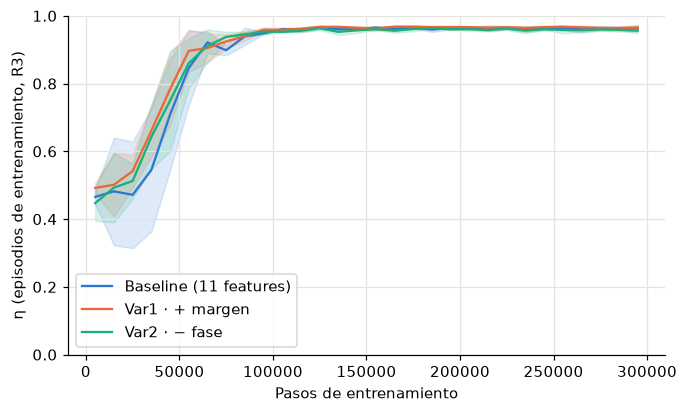

Guardado: results\tables\sprint4_curvas_aprendizaje.csv


In [10]:
BINS = np.linspace(0, 300_000, 31)
x = (BINS[:-1] + BINS[1:]) / 2
filas = []
fig, ax = plt.subplots(figsize=(7, 4))
for fs in FS:
    curvas = []
    for s in SEMILLAS_ENTREN:
        c = pd.read_csv(PILOTO / f"{fs}_R3_s{s}" / "curve.csv")
        curvas.append(c.groupby(pd.cut(c["timestep"], BINS), observed=False)["eta"].mean().to_numpy())
    curvas = np.array(curvas)
    media, desv = np.nanmean(curvas, axis=0), np.nanstd(curvas, axis=0)
    filas += [{"feature_set": fs, "paso": p, "eta_media": m, "eta_desv": d} for p, m, d in zip(x, media, desv)]
    ax.plot(x, media, color=FS_COLOR[fs], label=FS_ETIQUETA[fs])
    ax.fill_between(x, media - desv, media + desv, color=FS_COLOR[fs], alpha=0.15)
ax.set_xlabel("Pasos de entrenamiento")
ax.set_ylabel("η (episodios de entrenamiento, R3)")
ax.set_ylim(0, 1)
ax.legend()
fig.savefig(FIGURAS / "fig9_sprint4_curvas_aprendizaje.png", bbox_inches="tight", dpi=130)
plt.show()

curvas_aprendizaje = pd.DataFrame(filas)
guardar(curvas_aprendizaje, "curvas_aprendizaje")

Para decidir si la curva se aplanó: η medio en el primer y en el último 10 % del entrenamiento, y cuánto cambió en el último 20 %. Un cambio cercano a 0 al final indica que ya llegó a su meseta.

In [11]:
def tramo(g, desde, hasta):
    return g[(g["paso"] >= desde) & (g["paso"] < hasta)]["eta_media"].mean()


meseta = pd.DataFrame([{
    "conjunto": FS_ETIQUETA[fs],
    "eta_inicio (0–30k)": tramo(g, 0, 30_000),
    "eta_final (270–300k)": tramo(g, 270_000, 300_000),
    "cambio_ultimo_20%": tramo(g, 270_000, 300_000) - tramo(g, 240_000, 270_000),
    "desv_final_entre_semillas": g["eta_desv"].iloc[-3:].mean(),
} for fs, g in curvas_aprendizaje.groupby("feature_set", sort=False)])
guardar(meseta, "meseta")
meseta

Guardado: results\tables\sprint4_meseta.csv


,conjunto,eta_inicio (0–30k),eta_final (270–300k),cambio_ultimo_20%,desv_final_entre_semillas
0,Baseline (11 features),0.473,0.963,2.351e-04,0.007
1,Var1 · + margen,0.512,0.965,-2.325e-03,0.004
2,Var2 · − fase,0.484,0.958,-3.051e-04,0.005


Las tres variantes aprenden igual, pasan de η ≈ 0.5 a 0.96, se estabilizan antes de terminar el entrenamiento y sus semillas quedan casi iguales. En R3 no hay alto bias ni faltan datos. El problema está fuera de R3, donde las semillas del baseline dan 0.97, 0.03 y 0.00 en R1. Es alta varianza en la generalización, y entrenar más no la corregiría.



## 6. Checklist de validación

| Punto | ¿Cumple? | Cómo |
|---|---|---|
| Split correcto | Sí | Semillas de entrenamiento 1000 a 1002, banco 5500 a 5509 y evaluación con las de ajuste 5000 a 5019. Las de reporte (9000 en adelante) no se usan |
| Fit solo en train | Sí | La μ y σ de `VecNormalize` vienen del entrenamiento en R3 y se aplican congeladas (`obs_rms.npz`) |
| Seeds fijadas, mismo protocolo que semanas 5 y 6 | Sí | Mismos modelos y entorno Var3, con semillas fijas también para los reemplazos de la permutación |
| Sin cambios de datos entre baseline y evaluación | Sí | No se reentrena, solo se evalúa |
| Sin leakage | Sí | Ninguna feature usa información futura, todas se calculan con el estado actual o el paso anterior |
| Colinealidad bajo control | Sí | Las features colineales se permutan en grupo (fase y fracciones) |
| Logs completos | Sí | `logs/metrics_sprint4_importancia.txt` (última celda) y tablas en `results/tables/sprint4_*.csv` |

## 7. Decisión: qué features se quedan

El criterio de adopción de la clase es que haya una mejora consistente de η (media más alta o desviación más baja) y que el resultado sea estable entre semillas.

In [12]:
UMBRAL = 0.02  # diferencias de η menores se consideran ruido (20 episodios)
imp_guardada = leer("importancia")
est_guardada = leer("estabilidad").fillna("")


def patron(r3, r1):
    if r1 < -UMBRAL:
        return "estorba fuera de R3"
    if r3 > UMBRAL:
        return "la usa en R3" + (" y en R1" if r1 > UMBRAL else "")
    if r1 > UMBRAL:
        return "solo la usa en R1"
    return "ignorada"


filas = []
for (fs, g), t in imp_guardada.groupby(["feature_set", "grupo"]):
    fila = {"conjunto": FS_ETIQUETA[fs], "grupo": g}
    for c in NIVELES:
        v = t[t["condicion"] == c]["importancia"]
        top = est_guardada[(est_guardada["feature_set"] == fs) & (est_guardada["nivel"] == c)][f"top{TOP}_común"].iloc[0]
        fila[f"imp_{c}"] = v.mean()
        fila[f"desv_{c}"] = v.std()
        fila[f"top{TOP}_estable_{c}"] = "sí" if g in top.split(", ") else "no"
    fila["patrón"] = patron(fila["imp_R3"], fila["imp_R1"])
    filas.append(fila)

decision = pd.DataFrame(filas)
decision["orden"] = decision["grupo"].map(list(GRUPOS).index)
decision = decision.sort_values(["conjunto", "orden"]).drop(columns="orden")
guardar(decision, "decision")
decision.set_index(["conjunto", "grupo"])

Guardado: results\tables\sprint4_decision.csv


imp_R3  desv_R3 top5_estable_R3  \
conjunto               grupo                                                 
Baseline (11 features) centroide_x      2.833e-03    0.008              no   
                       centroide_y      1.451e-01    0.184              sí   
                       dispersion_x     6.833e-03    0.008              sí   
                       dispersion_y     1.867e-02    0.042              no   
                       fracciones       1.594e-01    0.227              no   
                       fase             5.325e-02    0.036              sí   
                       accion_previa_x -3.833e-03    0.003              no   
                       accion_previa_y  2.167e-03    0.005              no   
Var1 · + margen        centroide_x     -7.167e-03    0.003              no   
                       centroide_y      4.583e-03    0.009              no   
                       dispersion_x     1.242e-02    0.005              sí   
                       dispersion_y    -4.417e-03    0.004              no   
                       fracciones       4.142e-02    0.050              sí   
                       fase             2.393e-01    0.193              sí   
                       accion_previa_x  1.583e-03    0.002              no   
                       accion_previa_y  1.583e-03    0.005              no   
                       margen_control  -3.167e-03    0.005              no   
Var2 · − fase          centroide_x      5.075e-02    0.089              no   
                       centroide_y      8.558e-02    0.150              no   
                       dispersion_x     1.792e-02    0.033              no   
                       dispersion_y     1.175e-02    0.017              sí   
                       fracciones       3.169e-01    0.294              sí   
                       accion_previa_x  4.167e-04    0.003              no   
                       accion_previa_y  5.250e-03    0.009              no   

                                           imp_R1  desv_R1 top5_estable_R1  \
conjunto               grupo                                                 
Baseline (11 features) centroide_x      3.329e-01    0.553              sí   
                       centroide_y      1.042e-02    0.969              no   
                       dispersion_x    -2.692e-02    0.063              no   
                       dispersion_y    -2.811e-01    0.488              no   
                       fracciones       7.333e-03    0.018              no   
                       fase            -3.120e-01    0.540              no   
                       accion_previa_x -3.624e-01    0.524              no   
                       accion_previa_y -2.235e-01    0.380              no   
Var1 · + margen        centroide_x      0.000e+00    0.000              sí   
                       centroide_y      0.000e+00    0.000              sí   
                       dispersion_x     0.000e+00    0.000              sí   
                       dispersion_y     0.000e+00    0.000              no   
                       fracciones       0.000e+00    0.000              no   
                       fase            -3.204e-01    0.555              no   
                       accion_previa_x  0.000e+00    0.000              sí   
                       accion_previa_y  0.000e+00    0.000              sí   
                       margen_control  -3.220e-01    0.551              no   
Var2 · − fase          centroide_x     -4.833e-03    0.008              no   
                       centroide_y      7.500e-04    0.008              no   
                       dispersion_x     3.207e-01    0.558              no   
                       dispersion_y     3.333e-04    0.003              sí   
                       fracciones      -3.083e-03    0.003              no   
                       accion_previa_x  4.167e-04    0.002              sí   
                       accion_previa_y -1.417e-03    0.002      

De estos resultados podemos sacar desiciones para:

| Grupo | Decisión | Por qué |
|---|---|---|
| centroide_x | Se queda | Es la variable que usa la semilla del baseline que sí transfiere a R1 (al esconderla η cae de 0.97 a 0) y en la Var2 se usa en R3 (0.051). Describe el enjambre igual en todos los niveles |
| centroide_y | Se queda | Es de las más importantes en R3 (0.145 en el baseline y 0.086 en la Var2) y no estorba en la Var2 |
| dispersion_x | Se queda | En R3 aporta poco (0.007 a 0.018), pero la semilla 0 de la Var2 depende de ella en R1 (0.97) y no estorba en la Var2 |
| dispersion_y | Se queda, en revisión | Casi no se usa en R3 (0.012 a 0.019). En el baseline estorba en R1 en la semilla 1 (−0.84), pero en la Var2 es neutra (0.000) |
| fracciones | Se queda | Es la más importante en R3 (0.159 en el baseline y 0.317 en la Var2) y es neutra en R1 |
| fase | Sale | Se usa en R3 (0.053 en el baseline y 0.239 en la Var1), pero en R1 estorba: al esconderla η sube de 0.03 a 0.97 en la semilla 1 del baseline y de 0 a 0.96 en la semilla 2 de la Var1. Confirma la decisión del Sprint 3 |
| accion_previa_x | En revisión | No se usa en R3 (cerca de 0 en las tres variantes) y en el baseline estorba en R1 (−0.96 en la semilla 2). En la Var2 es neutra. Se propone probar quitarla en el siguiente sprint |
| accion_previa_y | En revisión | Igual que la acción previa en x: cerca de 0 en R3 y −0.66 en R1 en la semilla 1 del baseline. Neutra en la Var2 |
| margen_control | Sale | No se usa en R3 (−0.003) y en R1 estorba: al esconderlo η sube de 0 a 0.96 en la semilla 1 de la Var1. Confirma la decisión del Sprint 3 |

## 8. Conclusiones

### 8.1 Desempeño de cada conjunto de features (sin permutar)

η de las políticas sin permutar, en las semillas de ajuste. Es la referencia contra la que se midió cada importancia. La columna por semilla muestra si la transferencia a R1 depende de la semilla.

In [13]:
orig = leer("episodios_permutacion").query("grupo == 'original'")
por_semilla = orig.groupby(["feature_set", "condicion", "semilla_entren"])["eta"].mean()
filas = []
for fs in FS:
    fila = {"conjunto": FS_ETIQUETA[fs]}
    for c in NIVELES:
        v = por_semilla.loc[fs, c]
        fila[f"eta_{c}"] = v.mean()
        fila[f"desv_{c}"] = v.std()
        fila[f"eta_{c}_por_semilla"] = " / ".join(f"{x:.2f}" for x in v)
    fila["brecha_R3_R1"] = fila["eta_R3"] - fila["eta_R1"]
    filas.append(fila)
eta_original = pd.DataFrame(filas)
guardar(eta_original, "eta_original")
eta_original

Guardado: results\tables\sprint4_eta_original.csv


,conjunto,eta_R3,desv_R3,eta_R3_por_semilla,eta_R1,desv_R1,eta_R1_por_semilla,brecha_R3_R1
0,Baseline (11 features),0.964,0.008,0.97 / 0.97 / 0.95,0.333,0.553,0.97 / 0.03 / 0.00,0.631
1,Var1 · + margen,0.967,0.004,0.97 / 0.97 / 0.96,0.000,0.000,0.00 / 0.00 / 0.00,0.967
2,Var2 · − fase,0.966,0.008,0.97 / 0.96 / 0.96,0.969,0.004,0.97 / 0.97 / 0.97,-0.004


### 8.2 Hallazgos principales (datos)

Por conjunto de features: el grupo del que más depende la política en R3 y el que más estorba en R1.

In [14]:
filas = []
for conjunto, t in decision.groupby("conjunto", sort=False):
    mas_usado = t.loc[t["imp_R3"].idxmax()]
    mas_estorba = t.loc[t["imp_R1"].idxmin()]
    filas.append({"conjunto": conjunto,
                  "más importante en R3": mas_usado["grupo"], "imp_R3": mas_usado["imp_R3"],
                  "más negativo en R1": mas_estorba["grupo"], "imp_R1": mas_estorba["imp_R1"]})
hallazgos = pd.DataFrame(filas)
guardar(hallazgos, "hallazgos")
hallazgos

Guardado: results\tables\sprint4_hallazgos.csv


,conjunto,más importante en R3,imp_R3,más negativo en R1,imp_R1
0,Baseline (11 features),fracciones,0.159,accion_previa_x,-0.362
1,Var1 · + margen,fase,0.239,margen_control,-0.322
2,Var2 · − fase,fracciones,0.317,centroide_x,-0.005


### 8.3 Conclusiones

- En R3 las tres variantes rinden igual (η entre 0.964 y 0.967) y sus curvas de aprendizaje ya llegaron a la meseta. Por ello la diferencia entre ellas no está en lo bien que aprenden sino en como se comportan fuera de este R3. En R1 el baseline baja a 0.333, la Var1 a 0.000 y la Var2 se mantiene en 0.969 en las tres semillas.

- Las políticas que fallan en R1 no fallan porque no sepan controlar el enjambre sin flujo, sino porque una variable las engaña. Esto se nota al esconder la fase, el margen o la acción previa vemos que η vuelve a 0.96 o 0.97. En cambio, la Var2 se guía por el centroide, la dispersión y las fracciones que significan lo mismo en todos los niveles, y no tiene variables con importancia negativa en R1.

- Con esto la observación de la Var2 (sin fase, 9 features) pasa a la matriz de evaluación cruzada πRi(Rj) y el margen se descarta. La acción previa queda en revisión, ya que no se usa en R3 y en el baseline perjudicó la transferencia, así que se propone como trabajo siguiente probar una variante sin ella en el siguiente sprint.

- Otro trabajo que quedaa pendiente es confirmar esto con más semillas, ya que con 3 es un indicio y no un resultado confirmatorio, evaluar también en R2 y R4.

In [15]:
ruta = ROOT / "logs" / "metrics_sprint4_importancia.txt"
config = {"corridas": [c.name for c in CORRIDAS], "niveles": NIVELES,
          "semillas_episodio": f"{SEMILLAS_EP[0]}–{SEMILLAS_EP[-1]}",
          "semillas_banco": f"{SEMILLAS_BANCO[0]}–{SEMILLAS_BANCO[-1]}",
          "grupos": GRUPOS, "top": TOP, "umbral": UMBRAL}
with open(ruta, "w", encoding="utf-8") as f:
    f.write("# Métricas: sprint4_importancia\n\n")
    f.write("## Metadatos\n" + json.dumps(run_metadata(), indent=2, ensure_ascii=False) + "\n\n")
    f.write("## Configuración\n" + json.dumps(config, indent=2, ensure_ascii=False) + "\n\n")
    for titulo, df in [("η sin permutar", eta_original), ("Importancia R3", resumen_R3), ("Importancia R1", resumen_R1),
                       ("Estabilidad entre semillas", estabilidad), ("Tabla de decisión", decision),
                       ("Hallazgos", hallazgos), ("Meseta de las curvas de aprendizaje", meseta)]:
        f.write(f"## {titulo}\n" + df.to_string(float_format="%.3f") + "\n\n")
print(f"Log guardado en {ruta.relative_to(ROOT)}")
print(f"Tiempo total: {(time.time() - T_INICIO) / 60:.1f} min")

Log guardado en logs\metrics_sprint4_importancia.txt
Tiempo total: 17.3 min
